## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Roney Nguyen

**Date:** 10/12/2026

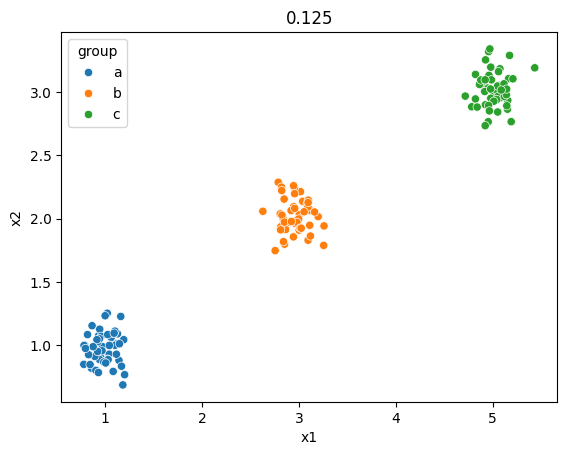

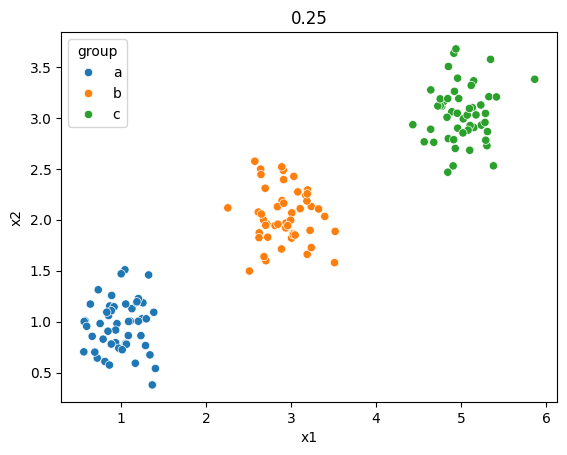

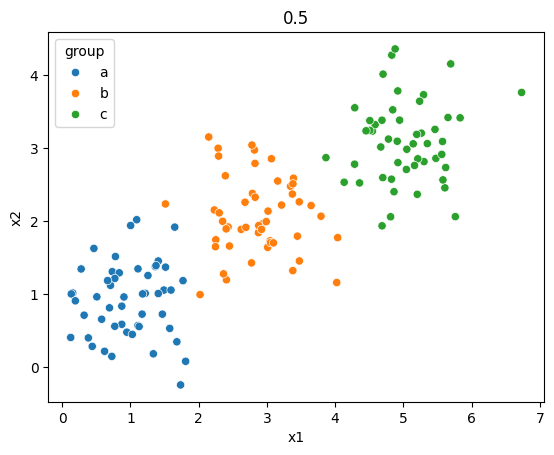

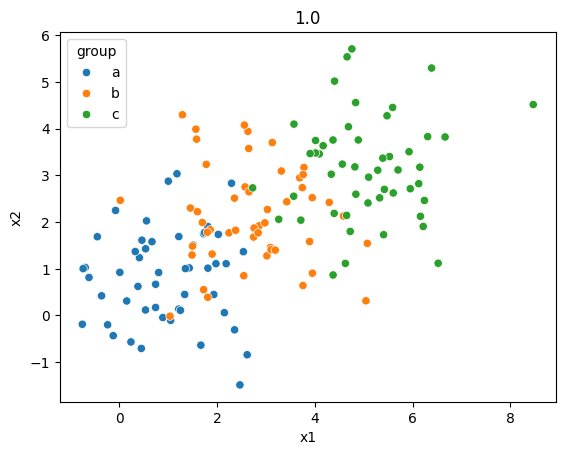

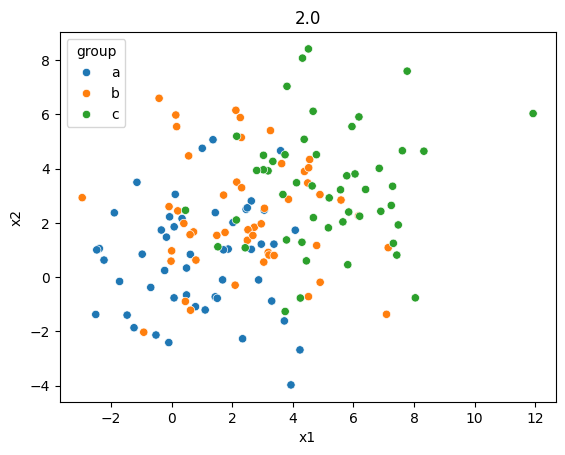

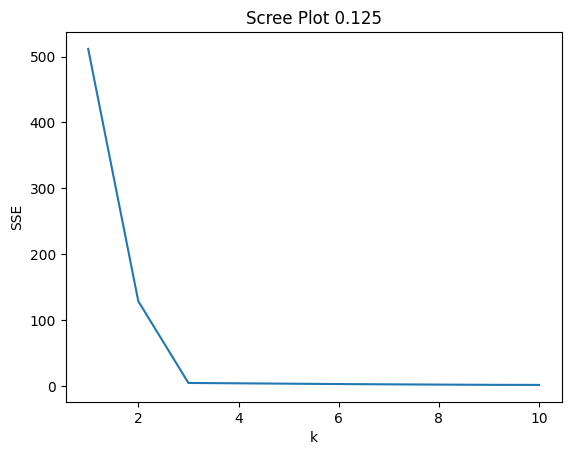

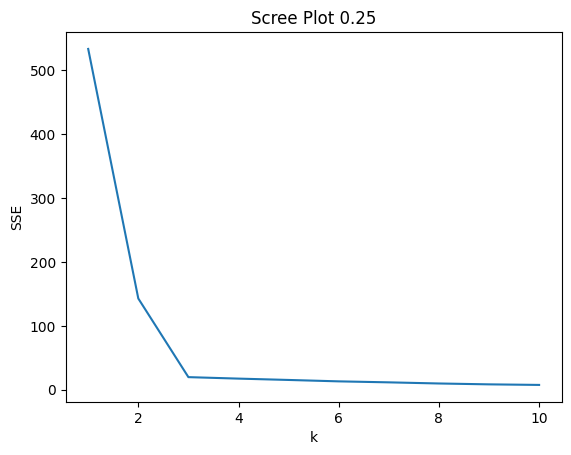

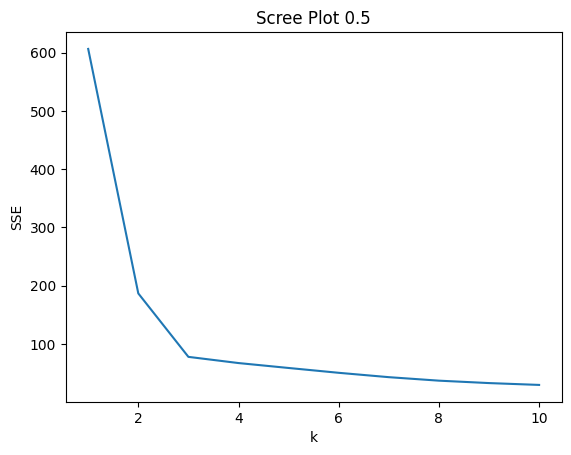

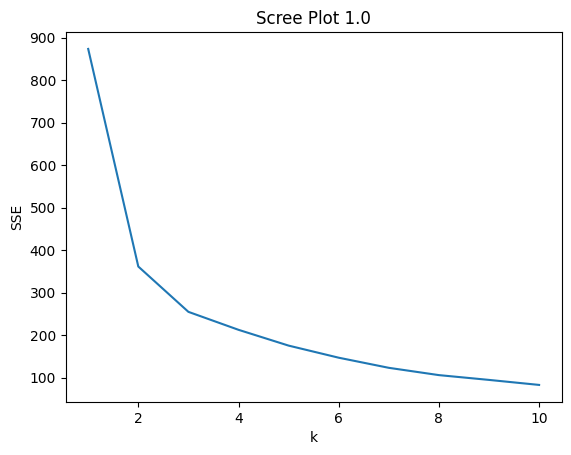

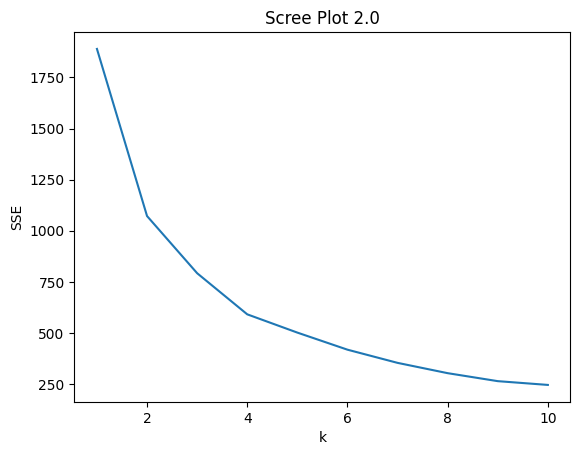

In [13]:
# Your Phase 1 solution to the problem goes here.
#1 Run code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#2 Make scatterplots of the $(X1,X2)$ points by group for each of the datasets.
sns.scatterplot(data=df0_125,x='x1', y='x2',hue='group').set(title="0.125")
plt.show()
sns.scatterplot(data=df0_25,x='x1', y='x2',hue='group').set(title="0.25")
plt.show()
sns.scatterplot(data=df0_5,x='x1', y='x2',hue='group').set(title="0.5")
plt.show()
sns.scatterplot(data=df1_0,x='x1', y='x2',hue='group').set(title="1.0")
plt.show()
sns.scatterplot(data=df2_0,x='x1', y='x2',hue='group').set(title="2.0")
plt.show()
#As noise goes up, the points inside the clusters become more and more spaced out from eachother, each cluster becomes harder and harder to be defined visually.

#3 Create a scree plot for each of the datasets
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.125", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.25", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.5", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 1.0", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 2.0", xlabel="k", ylabel="SSE")
plt.show()

#4 The intuition of the elbow is that it represents the best spot where adding more clusters shows diminishing returns. 
#In our scatter plot when we had low noise, it is visually clear that there are 3 clusters, as noise increase it becomes increasingly harder to see that. 
#This is the backed up by our elbow/scree plot where low noises show that after 3 clusters there are virtually no changes to error, as noise increases, the clusters overlap more, and adding clusters continues to noticeably reduce SSE, making the elbow harder to identify.


Index(['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP',
       'Percent of Government Spending', 'Spending per Capita'],
      dtype='str') 

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

index                             148
Year                              148
Country                           148
Spending (2020 USD)               148
Percent of GDP                    148
Percent of Government Spending    148
Spending per Capita               148
dtype: int64


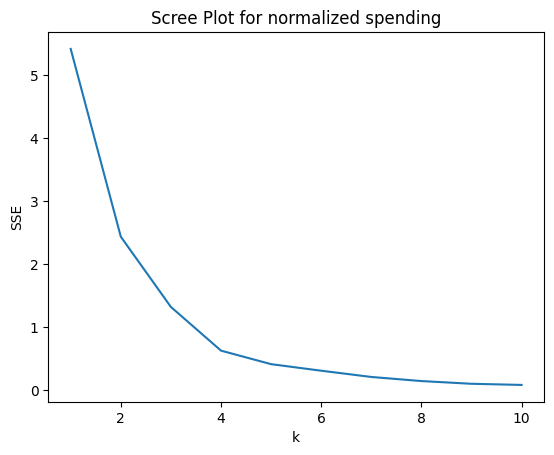

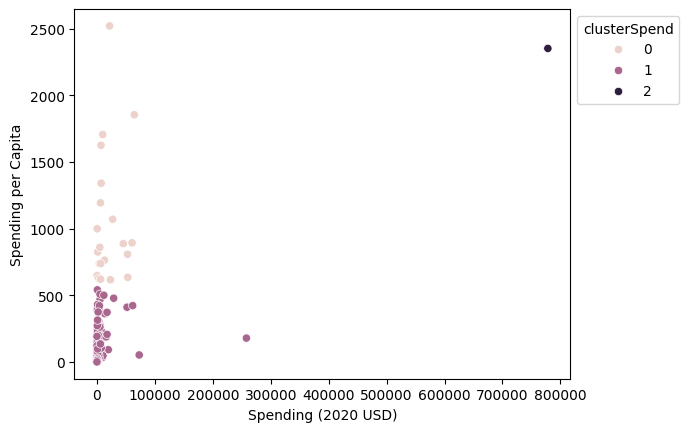

              index                                                            \
              count         mean          std     min     25%     50%     75%   
clusterSpend                                                                    
0              21.0  2913.904762  1632.102874   236.0  1834.0  2922.0  4044.0   
1             126.0  2795.984127  1652.593453    32.0  1332.5  2769.0  4205.5   
2               1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   

                       Year          ... Percent of Government Spending  \
                 max  count    mean  ...                            75%   
clusterSpend                         ...                                  
0             5506.0   21.0  2020.0  ...                       0.110270   
1             5880.0  126.0  2020.0  ...                       0.077917   
2             5540.0    1.0  2020.0  ...                       0.081976   

                       Spending per Capita                    

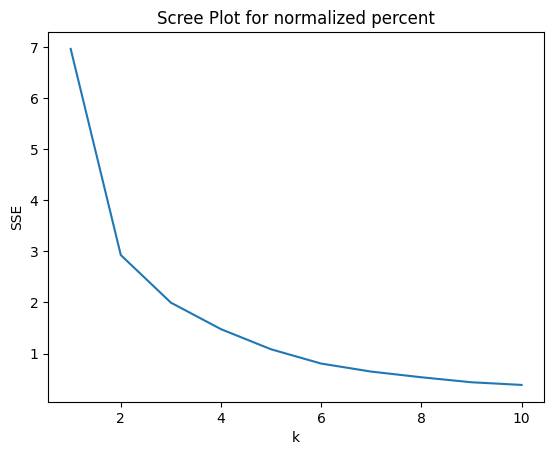

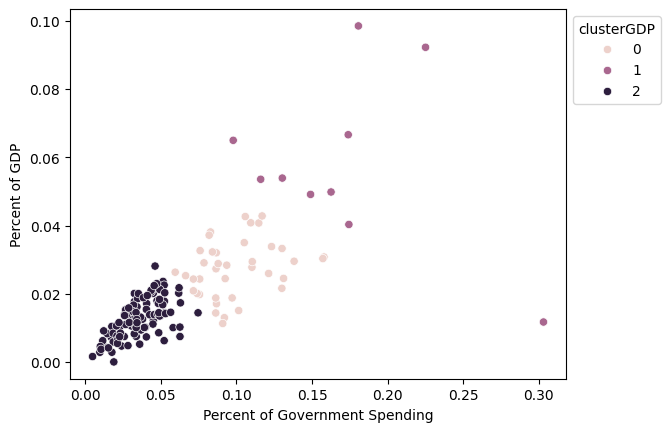

           index                                                           \
           count         mean          std    min     25%     50%     75%   
clusterGDP                                                                  
0           39.0  2894.974359  1789.517893  338.0  1052.0  2854.0  4741.0   
1           10.0  2184.200000  1773.299110  100.0   329.5  2650.0  3763.5   
2           99.0  2871.515152  1590.144034   32.0  1647.0  2956.0  4197.0   

                    Year          ... Spending per Capita               \
               max count    mean  ...                 75%          max   
clusterGDP                        ...                                    
0           5540.0  39.0  2020.0  ...          209.705770  2351.631858   
1           4486.0  10.0  2020.0  ...         1517.266870  2520.398541   
2           5880.0  99.0  2020.0  ...          367.649743  1341.058851   

           clusterSpend                                               
                  cou

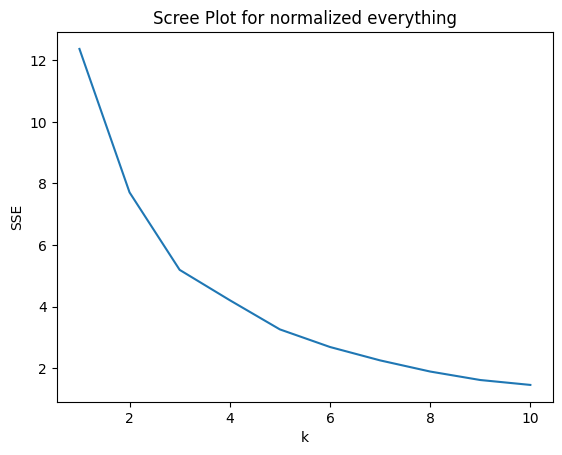

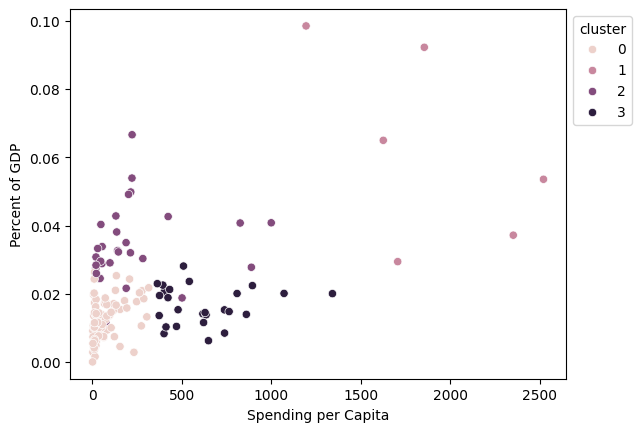

        index                                                            \
        count         mean          std     min     25%     50%     75%   
cluster                                                                   
0        86.0  2841.744186  1630.948935    32.0  1536.5  2837.0  4205.5   
1         6.0  4038.333333  1113.917352  2582.0  3202.5  4265.0  4613.5   
2        30.0  2542.333333  1812.819719   100.0   763.0  2616.0  3729.5   
3        26.0  2851.384615  1592.766225   236.0  1732.0  2854.0  4214.0   

                 Year          ... clusterSpend      clusterGDP            \
            max count    mean  ...          75%  max      count      mean   
cluster                        ...                                          
0        5880.0  86.0  2020.0  ...          1.0  1.0       86.0  1.697674   
1        5540.0   6.0  2020.0  ...          0.0  2.0        6.0  0.666667   
2        5438.0  30.0  2020.0  ...          1.0  1.0       30.0  0.200000   
3        550

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

#1
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
print(df.columns, "\n")
print(df.dtypes, "\n")

df = df.loc[df["Year"] == 2020].dropna().copy()
print(df.count())
#also got 148, no need to for further since ended as int64

#2, min max normalize 
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized spending", xlabel="k", ylabel="SSE")
plt.show()
#between 2/3, but choosing 3
#Create scatter plot
optimal_k = 3
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["clusterSpend"] = best_kmeans.fit_predict(X)
ax = sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='clusterSpend')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('clusterSpend').describe())
#There were 126, 1, and  21 countries in the 3 clusters. Most countries were grouped together with lower military spending, while the smaller cluster generally had higher spending or spending per capita
#Find U.S
print(df.loc[df["Country"] == "United States of America", ["Country", "clusterSpend"] + features])
#The United States has the highest total spending and is an outlier that has its own cluster because of how much spending it does.

#3
features=["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized percent", xlabel="k", ylabel="SSE")
plt.show()
#Best ones seems to be like 3/4, im leaning towards 3
optimal_k = 3
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["clusterGDP"] = best_kmeans.fit_predict(X)
ax = sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='clusterGDP')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('clusterGDP').describe())
#K = 3 seemed to be fine, Our cluster has 39, 10, 99 groups.
#Find U.S
print(df.loc[df["Country"] == "United States of America", ["Country", "clusterGDP"] + features])
#US spends about 8.2% of its government spending and 3.72% of GDP on the military. Both are above the dataset averages. Unlike part 2, the United States is not as much of an outlier because we are comparing spending relative to the country's economy rather than the total amount spent.
#Compared to Part 2 results seems to be a harder to determine, the scree plot has a slightly harder to determine elbow, and the scatter plot has is less defined as the earlier, but we can still see the patterns of clusters. ALongside that the US is not an outtlier, but rather is contributes to the average.



features=["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized everything", xlabel="k", ylabel="SSE")
plt.show()
#Best ones seems to be like 4/5, im leaning towards 4
optimal_k = 4
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["cluster"] = best_kmeans.fit_predict(X)
#uses 1 from each since scatter is only 2d
ax = sns.scatterplot(data=df, x='Spending per Capita', y='Percent of GDP', hue='cluster')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('cluster').describe())
#Find US
print(df.loc[df["Country"] == "United States of America", ["Country", "cluster"] + features])
#US is in cluster 1 with only 6 countries, spending at around 778 billion USD and spends about 2352 USD per capita, its military spending is makes up 8.2% of government spending and 3.72% of GDP. It alongside the others in it cluster are outliers compared to the other countries.
#Compared to the other 2 graphs, this data needed more clusters maybe because it combines both data and had a less obvious elbow. Combining all four variables gave us a more detailed view of military spending and show that it had similarities with other countries despite being an outlier.

#5
#K-means clustering did find some useful patterns in military spending. Most countries were grouped together, while smaller groups had higher spending or spending percentages. The United States was an outlier in total military spending but not one in spending as a percentage of its economy. Overall, K-means was useful for finding general patterns, although the results depended on the number of clusters chosen.




## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 21ad6bc043fae78b38553d5ca0822468e6d98da4
- **AI tool and model used:** ChatGPT-6

### *Prompts used

1. Review answers and comments for part 1 and 2, send concise numbered list of improvements and fixes to my code/answers.
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Q1, Part 3 — Scree plots: Add an explanation directly under Part 3. Mention that higher noise increases SSE and makes the elbow less distinct, making it harder to confidently select \(k=3\).
2. Q2, Part 1 - len(df) would be clearer than df.count() for checking the number of countries
3. Q2, Part 2 — Choosing k: Your cluster sizes of 126, 21, and 1 are correct. However, the scree plot shows substantial SSE reductions through \(k=4\), making that a defensible elbow. You can keep \(k=3\), but mention that it separates the U.S. into its own cluster rather than claiming a definitive elbow at 3.
4. Q2, Parts 2–4 — Describe tables: Your .groupby().describe() code works, but includes unrelated numeric columns. Restrict it to the clustering features: print(df.groupby('clusterSpend')[features].describe().T)
5. Q2, Part 4 — Four-variable clustering: Avoid saying the six countries are all outliers. Instead, say they share relatively high per-capita and military spending percentages

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I had mentioned the answer in part4 of q1, but didn't realize part3 asked to specifically explain it for that question, so yes. |
| 2 | Deny | Serves it purpose, would be better but virtually the same. |
| 3 | Deny | I think choosing 3 was fine, one of group had 1 cluster and to me it seemed like 3 from the scatter plot and theres no right answering for best k.|
| 4 | Accept | Make senses, the describe table was a bit hard for me to read at first anyways|
| 5 | Accept | More accurate |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

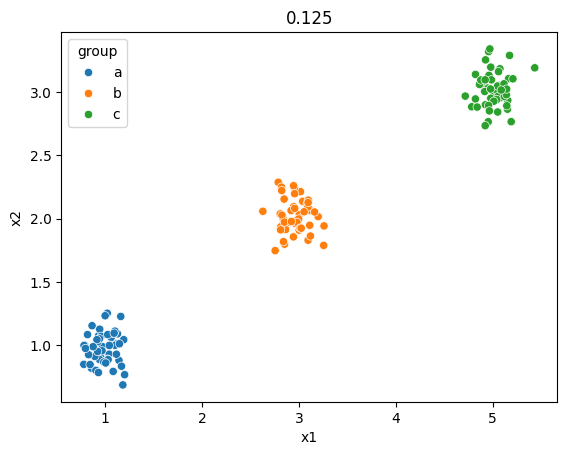

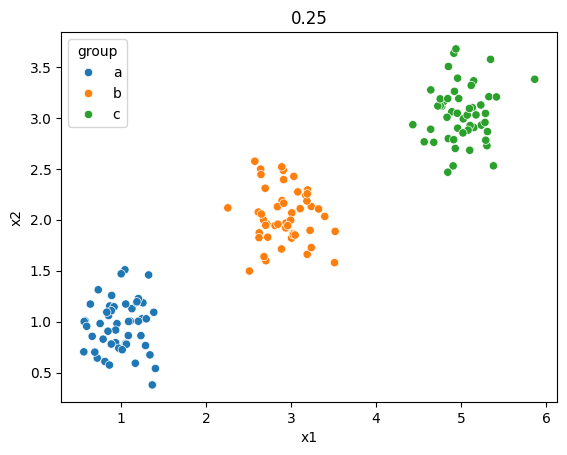

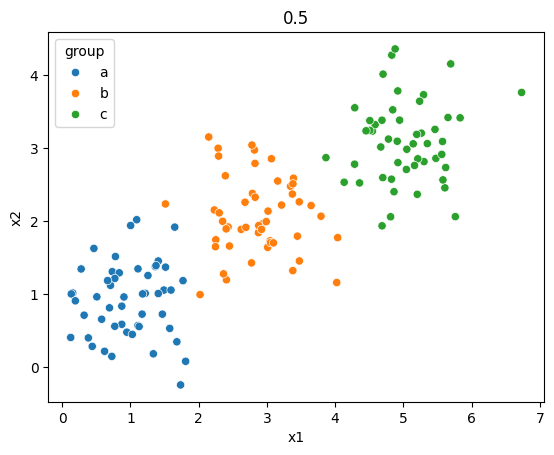

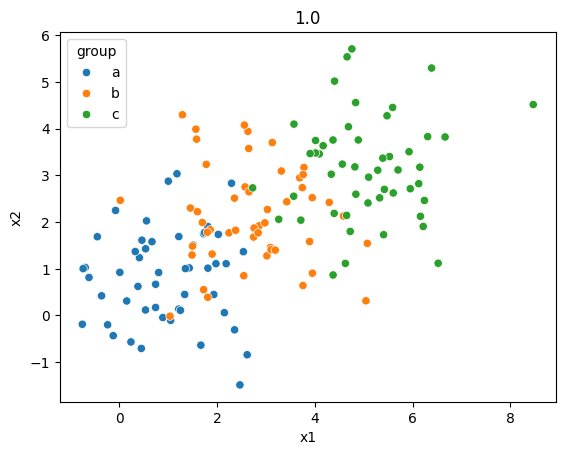

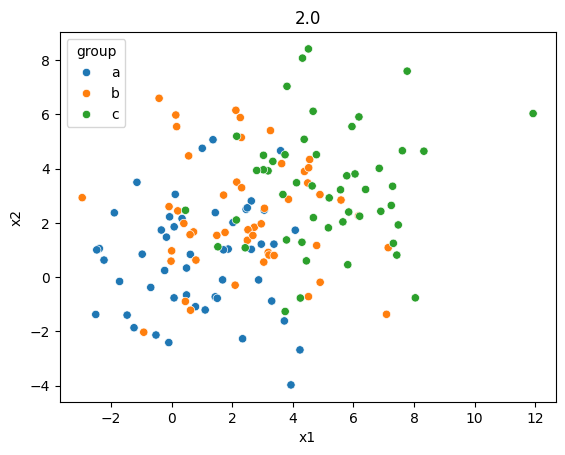

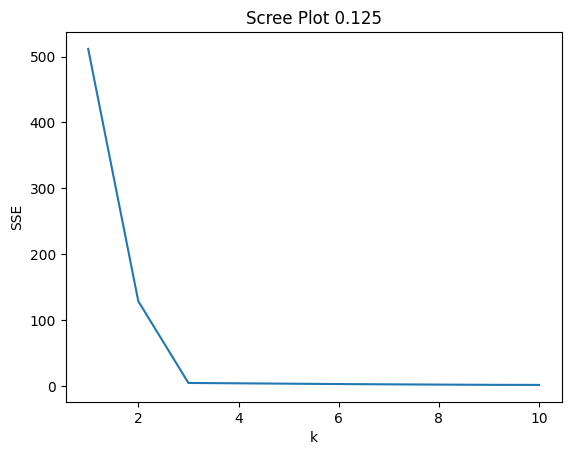

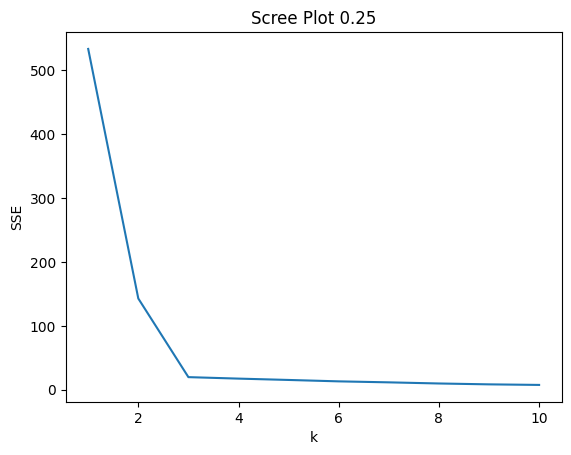

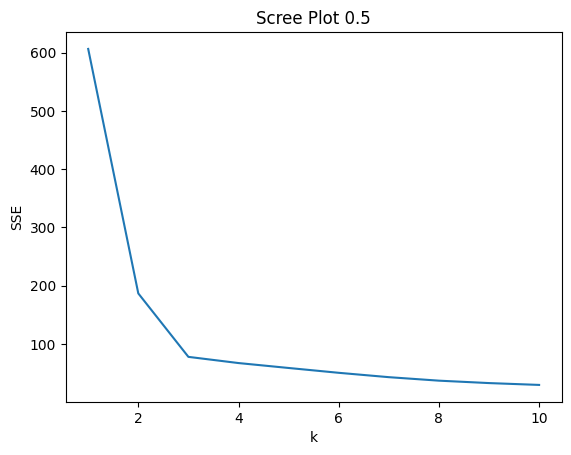

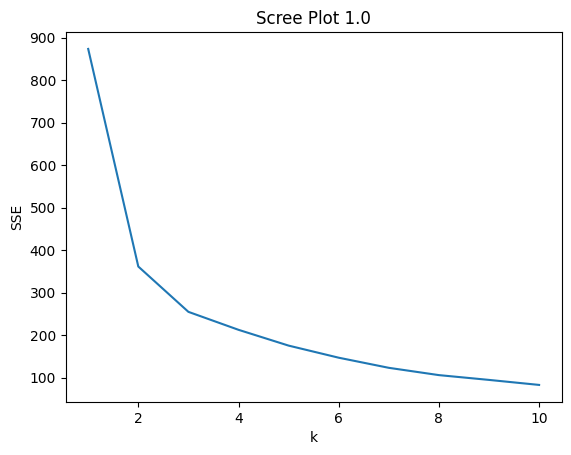

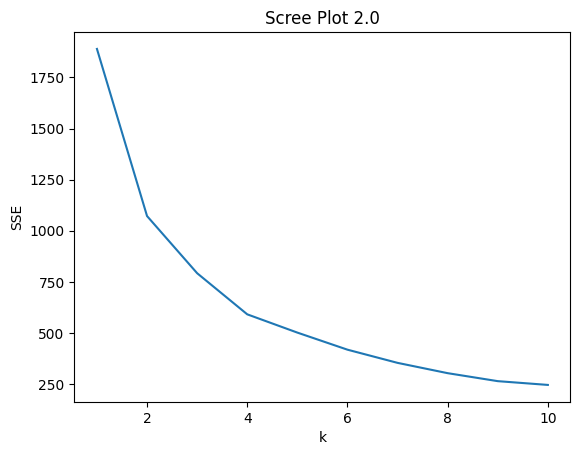

In [ ]:
# Your Phase 2 solution to the problem goes here.
# Your Phase 1 solution to the problem goes here.
#1 Run code
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
import seaborn as sns

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#2 Make scatterplots of the $(X1,X2)$ points by group for each of the datasets.
sns.scatterplot(data=df0_125,x='x1', y='x2',hue='group').set(title="0.125")
plt.show()
sns.scatterplot(data=df0_25,x='x1', y='x2',hue='group').set(title="0.25")
plt.show()
sns.scatterplot(data=df0_5,x='x1', y='x2',hue='group').set(title="0.5")
plt.show()
sns.scatterplot(data=df1_0,x='x1', y='x2',hue='group').set(title="1.0")
plt.show()
sns.scatterplot(data=df2_0,x='x1', y='x2',hue='group').set(title="2.0")
plt.show()
#As noise goes up, the points inside the clusters become more and more spaced out from eachother alongside the SSE value in the x-axis, each cluster becomes harder and harder to be defined visually.

#3 Create a scree plot for each of the datasets
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_125[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.125", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_25[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.25", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df0_5[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 0.5", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df1_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 1.0", xlabel="k", ylabel="SSE")
plt.show()

ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(df2_0[['x1', 'x2']]).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot 2.0", xlabel="k", ylabel="SSE")
plt.show()
#The level of noise makes the elbow harder to discern what is the best k to be chosen.

#4 The intuition of the elbow is that it represents the best spot where adding more clusters shows diminishing returns. 
#In our scatter plot when we had low noise, it is visually clear that there are 3 clusters, as noise increase it becomes increasingly harder to see that. 
#This is the backed up by our elbow/scree plot where low noises show that after 3 clusters there are virtually no changes to error, as noise increases, the clusters overlap more, and adding clusters continues to noticeably reduce SSE, making the elbow harder to identify.


Index(['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP',
       'Percent of Government Spending', 'Spending per Capita'],
      dtype='str') 

index                               int64
Year                                int64
Country                               str
Spending (2020 USD)               float64
Percent of GDP                    float64
Percent of Government Spending    float64
Spending per Capita               float64
dtype: object 

index                             148
Year                              148
Country                           148
Spending (2020 USD)               148
Percent of GDP                    148
Percent of Government Spending    148
Spending per Capita               148
dtype: int64


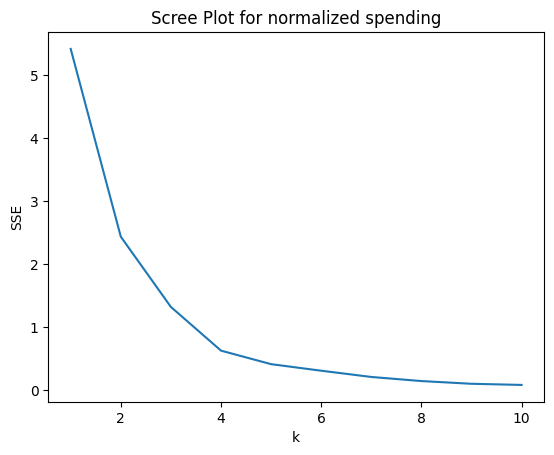

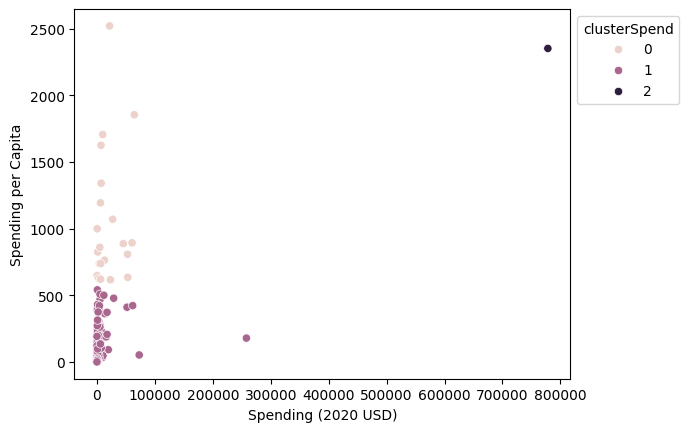

clusterSpend                          0              1              2
Spending (2020 USD) count     21.000000     126.000000       1.000000
                    mean   19975.991473    5943.346303  778397.200000
                    std    21749.736747   24858.961064            NaN
                    min      405.790494       8.622460  778397.200000
                    25%     4980.428135     162.761743  778397.200000
                    50%     7269.880030     580.758315  778397.200000
                    75%    27300.894701    3225.333414  778397.200000
                    max    64558.400000  257973.429834  778397.200000
Spending per Capita count     21.000000     126.000000       1.000000
                    mean    1046.433509     122.034996    2351.631858
                    std      501.631845     140.041183            NaN
                    min      616.854430       0.580129    2351.631858
                    25%      737.690186      18.505805    2351.631858
                    

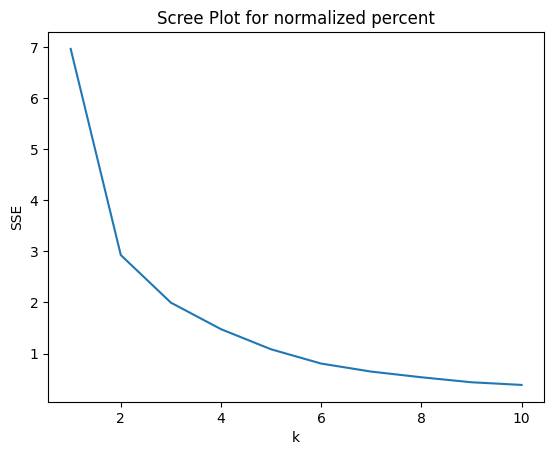

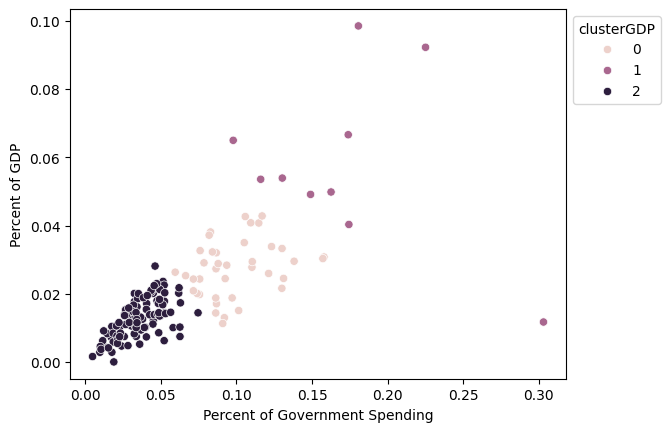

clusterGDP                                    0          1          2
Percent of Government Spending count  39.000000  10.000000  99.000000
                               mean    0.098683   0.171289   0.035777
                               std     0.024125   0.058725   0.014549
                               min     0.059520   0.097882   0.004896
                               25%     0.082430   0.135010   0.025921
                               50%     0.092044   0.168248   0.034261
                               75%     0.112633   0.179081   0.047402
                               max     0.157918   0.303027   0.074624
Percent of GDP                 count  39.000000  10.000000  99.000000
                               mean    0.027412   0.058071   0.012664
                               std     0.008191   0.024867   0.005681
                               min     0.011317   0.011742   0.000054
                               25%     0.021254   0.049297   0.008393
                    

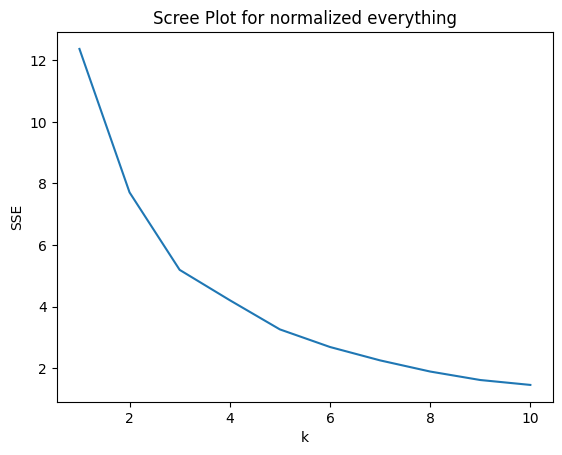

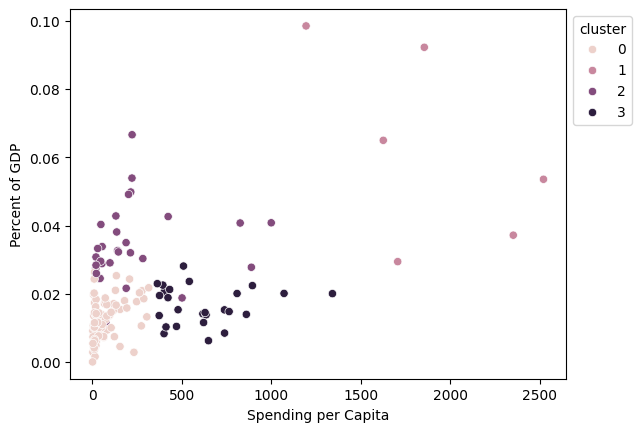

cluster                                           0              1  \
Spending (2020 USD)            count      86.000000       6.000000   
                               mean     4513.543790  147964.582042   
                               std     27841.230783  309635.189564   
                               min         8.622460    6095.708713   
                               25%        81.022976    7700.424616   
                               50%       288.061512   15897.570598   
                               75%      1138.618231   53872.942442   
                               max    257973.429834  778397.200000   
Spending per Capita            count      86.000000       6.000000   
                               mean       70.290644    1875.150751   
                               std        81.690590     489.800206   
                               min         0.580129    1193.598730   
                               25%        11.522275    1645.301864   
                    

In [20]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

#1
df = pd.read_csv('data/SIPRI Military Expenditure Database.csv')
print(df.columns, "\n")
print(df.dtypes, "\n")

df = df.loc[df["Year"] == 2020].dropna().copy()
print(df.count())
#also got 148, no need to for further since ended as int64

#2, min max normalize 
features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized spending", xlabel="k", ylabel="SSE")
plt.show()
#between 2/3, but choosing 3
#Create scatter plot
optimal_k = 3
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["clusterSpend"] = best_kmeans.fit_predict(X)
ax = sns.scatterplot(data=df, x='Spending (2020 USD)', y='Spending per Capita', hue='clusterSpend')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('clusterSpend')[features].describe().T)
#There were 126, 1, and  21 countries in the 3 clusters. Most countries were grouped together with lower military spending, while the smaller cluster generally had higher spending or spending per capita
#Find U.S
print(df.loc[df["Country"] == "United States of America", ["Country", "clusterSpend"] + features])
#The United States has the highest total spending and is an outlier that has its own cluster because of how much spending it does.

#3
features=["Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized percent", xlabel="k", ylabel="SSE")
plt.show()
#Best ones seems to be like 3/4, im leaning towards 3
optimal_k = 3
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["clusterGDP"] = best_kmeans.fit_predict(X)
ax = sns.scatterplot(data=df, x='Percent of Government Spending', y='Percent of GDP', hue='clusterGDP')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('clusterGDP')[features].describe().T)
#K = 3 seemed to be fine, Our cluster has 39, 10, 99 groups.
#Find U.S
print(df.loc[df["Country"] == "United States of America", ["Country", "clusterGDP"] + features])
#US spends about 8.2% of its government spending and 3.72% of GDP on the military. Both are above the dataset averages. Unlike part 2, the United States is not as much of an outlier because we are comparing spending relative to the country's economy rather than the total amount spent.
#Compared to Part 2 results seems to be a harder to determine, the scree plot has a slightly harder to determine elbow, and the scatter plot has is less defined as the earlier, but we can still see the patterns of clusters. ALongside that the US is not an outtlier, but rather is contributes to the average.



features=["Spending (2020 USD)", "Spending per Capita", "Percent of Government Spending", "Percent of GDP"]
unscaled = df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])
#Scree plot to determine best cluster
ks = np.arange(1, 11)
SSE = [
    KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
    .fit(X).inertia_
    for k in ks
]
sns.lineplot(x=ks, y=SSE).set(title="Scree Plot for normalized everything", xlabel="k", ylabel="SSE")
plt.show()
#Best ones seems to be like 4/5, im leaning towards 4
optimal_k = 4
best_kmeans = KMeans(
    n_clusters=optimal_k, max_iter=300, n_init=10, random_state=0
)
df["cluster"] = best_kmeans.fit_predict(X)
#uses 1 from each since scatter is only 2d
ax = sns.scatterplot(data=df, x='Spending per Capita', y='Percent of GDP', hue='cluster')
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))
plt.show()
#Describe table
print(df.groupby('cluster')[features].describe().T)
#Find US
print(df.loc[df["Country"] == "United States of America", ["Country", "cluster"] + features])
#US is in cluster 1 with only 6 countries, spending at around 778 billion USD and spends about 2352 USD per capita, its military spending is makes up 8.2% of government spending and 3.72% of GDP. The countries in its cluster share relatively high per-capita and military spending percentages.
#Compared to the other 2 graphs, this data needed more clusters maybe because it combines both data and had a less obvious elbow. Combining all four variables gave us a more detailed view of military spending and show that it had similarities with other countries despite being an outlier.

#5
#K-means clustering did find some useful patterns in military spending. Most countries were grouped together, while smaller groups had higher spending or spending percentages. The United States was an outlier in total military spending but not one in spending as a percentage of its economy. Overall, K-means was useful for finding general patterns, although the results depended on the number of clusters chosen.




### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The main improvements that AI gave to me that directly affected my code and answers were making my describe tables easier to read and helping me answer questions that I had missed. For example, AI suggested that I only include the variables used for clustering in my describe tables instead of showing every numeric column. It also pointed out that I did not directly explain how noise affects the elbow in Q1 Part 3, even though I had mentioned it in Part 4. Other than that, most suggestions were minor clarifications to my explanations, especially when choosing the best k. This was useful because it helped me question my original decisions and made me look more closely at the scree plots instead of assuming my answers were correct. Some limitations were redundancy as I decided not to change some of my code because it wouldn't really affect my answer or improve it. I verified the suggestions by looking back at my scree plots, comparing different values of k, and checking that my cluster counts and descriptions matched my results. My main concern is that choosing the best k is still subjective because some of the elbow plots were unclear, so I am unsure if changing my choices would actually make my answers more accurate.